# 1. Read the file

In [2]:
from pathlib import Path
import pandas as pd

# need to change to the real path
folder = Path("/Users/densoul/Desktop/600")
input_file = folder / "cleaned_latest_data.csv"

data = pd.read_csv(
    input_file,
    dtype={"Participant ID": "string"},
    low_memory=False,
)

data.columns = data.columns.str.strip()

print(f"Records: {len(data):,}")
display(data.head())

Records: 13,053


,Participant ID,Survey year,Immediate recall,Delayed recall,Serial 7s,Backwards counting,Derived 0-27 cognition score,Hypertension,Diabetes,Cancer,...,Chronic Disease Burden,Age,Sex,Race/ethnicity,Education,Marital status,Smoking,BMI,Interview mode,Proxy respondent
0,010001010,2022,4.0,0.0,5.0,2.0,11.0,0.0,0.0,0.0,...,0.0,83.0,1,Non-Hispanic White,12.0,8.0,0.0,19.5,1.0,0.0
1,010003030,2022,5.0,2.0,4.0,2.0,13.0,1.0,0.0,0.0,...,5.0,66.0,2,Non-Hispanic White,16.0,7.0,0.0,36.0,1.0,0.0
2,010004040,2022,7.0,5.0,5.0,2.0,19.0,1.0,0.0,0.0,...,2.0,77.0,2,Non-Hispanic White,12.0,1.0,0.0,30.1,1.0,0.0
3,010013040,2022,5.0,6.0,5.0,2.0,18.0,1.0,0.0,0.0,...,1.0,74.0,2,Non-Hispanic White,13.0,5.0,0.0,25.2,1.0,0.0
4,010038010,2022,4.0,4.0,5.0,2.0,15.0,1.0,0.0,0.0,...,2.0,85.0,1,Non-Hispanic White,16.0,1.0,0.0,22.8,1.0,0.0


# 2.Redefine the numerical codes for each race category

In [3]:
race_mapping = {
    "Non-Hispanic White": 0,
    "Non-Hispanic Other": 1,
    "Non-Hispanic Black": 2,
    "Hispanic": 3,
}

race = data["Race/ethnicity"].astype("string").str.strip()

invalid = race.isna() | ~race.isin(race_mapping)
if invalid.any():
    raise ValueError(
        f"Missing or unexpected race values: "
        f"{race.loc[invalid].unique().tolist()}"
    )

data["Race/ethnicity"] = race.map(race_mapping).astype("int64")

print("Race/ethnicity counts after recoding:")
print(data["Race/ethnicity"].value_counts().sort_index())

Race/ethnicity counts after recoding:
Race/ethnicity
0    8186
1     375
2    2616
3    1876
Name: count, dtype: int64


In [4]:
print("Data types:")
print(data.dtypes)

non_numeric = data.select_dtypes(exclude="number").columns.tolist()
print("\nNon-numeric columns:", non_numeric)

model_columns = data.drop(columns=["Participant ID"])

print(
    "\nAll remaining columns are numeric:",
    model_columns.select_dtypes(exclude="number").empty,
)

Data types:
Participant ID                   string
Survey year                       int64
Immediate recall                float64
Delayed recall                  float64
Serial 7s                       float64
Backwards counting              float64
Derived 0-27 cognition score    float64
Hypertension                    float64
Diabetes                        float64
Cancer                          float64
Chronic lung disease            float64
Heart disease                   float64
Stroke                          float64
Arthritis                       float64
Chronic Disease Burden          float64
Age                             float64
Sex                               int64
Race/ethnicity                    int64
Education                       float64
Marital status                  float64
Smoking                         float64
BMI                             float64
Interview mode                  float64
Proxy respondent                float64
dtype: object

Non-numeric c

# 3.Pre-processing
## Define X1 and X2

In [5]:
demographic_features = [ "Age", "Sex", "Race/ethnicity", "Education", "Marital status"]

health_features = ["Smoking","BMI"]

# Model 1: Demographics + health condition
x1_features = demographic_features + health_features

# Model 2: Demographics + health condition + Chronic Disease Burden
x2_features = x1_features + ["Chronic Disease Burden"]

X1 = data[x1_features].copy()
X2 = data[x2_features].copy()

print("Model 1 features:", X1.columns.tolist())
print("Model 1 shape:", X1.shape)

print("\nModel 2 features:", X2.columns.tolist())
print("Model 2 shape:", X2.shape)


Model 1 features: ['Age', 'Sex', 'Race/ethnicity', 'Education', 'Marital status', 'Smoking', 'BMI']
Model 1 shape: (13053, 7)

Model 2 features: ['Age', 'Sex', 'Race/ethnicity', 'Education', 'Marital status', 'Smoking', 'BMI', 'Chronic Disease Burden']
Model 2 shape: (13053, 8)


## Define Y

In [6]:
# Outcome: Cognitive Score (0–27)
Y = data["Derived 0-27 cognition score"].copy()

print("Outcome:",Y.name)
print("Shape:", Y.shape)
print("Missing values:", Y.isna().sum())
print("Score range:", Y.min(), "to", Y.max())

assert X1.index.equals(Y.index)
assert X2.index.equals(Y.index)

Outcome: Derived 0-27 cognition score
Shape: (13053,)
Missing values: 0
Score range: 0.0 to 27.0


## Split the Data into Training and Test Sets

Use `train_test_split()` to divide the data into 70% training and 30% test sets.

- **X1:** Demographics + health condition (Model 1).
- **X2:** Demographics + health condition + Chronic Disease Burden (Model 2).
- **y:** Cognitive Score (0–27).

Split X1, X2, and y together so both models use the same participants in their training and test sets. Set `shuffle=True` to shuffle the records before splitting and `random_state=3` to make the split reproducible.

Use the training set to fit the models and the test set to evaluate and compare their predictive performance. Fit any preprocessing steps on the training set only, then apply them to the test set.

In [7]:
from sklearn.model_selection import train_test_split

(X1_trainset,X1_testset,X2_trainset,X2_testset,Y_trainset,Y_testset,) = train_test_split(
    X1,X2,Y, test_size=0.3,random_state=3,shuffle=True,)

# Check that both models use the same records
assert X1_trainset.index.equals(X2_trainset.index)
assert X1_trainset.index.equals(Y_trainset.index)
assert X1_testset.index.equals(X2_testset.index)
assert X1_testset.index.equals(Y_testset.index)

print("X1 training set:", X1_trainset.shape)
print("X1 test set:", X1_testset.shape)
print("X2 training set:", X2_trainset.shape)
print("X2 test set:", X2_testset.shape)
print("y training set:", Y_trainset.shape)
print("y test set:", Y_testset.shape)

X1 training set: (9137, 7)
X1 test set: (3916, 7)
X2 training set: (9137, 8)
X2 test set: (3916, 8)
y training set: (9137,)
y test set: (3916,)


## Step 1 — Import XGBoost

Import XGBRegressor to build regression models that predict Cognitive Score (Y).

Both models will use the same training and test participants as the linear regression models.

In [8]:
from xgboost import XGBRegressor

## Step 2 — Check the Training and Test Data

Confirm that X1, X2, and Y contain the same participants in the same order within each set.

Check for missing or infinite values and ensure that training and test records do not overlap. Use the existing split to keep comparisons with linear regression consistent.

In [9]:
import numpy as np

# Check that predictors and outcomes are aligned
assert X1_trainset.index.equals(X2_trainset.index)
assert X1_trainset.index.equals(Y_trainset.index)

assert X1_testset.index.equals(X2_testset.index)
assert X1_testset.index.equals(Y_testset.index)

# Check for missing or infinite values
datasets = {
    "X1_trainset": X1_trainset,
    "X2_trainset": X2_trainset,
    "Y_trainset": Y_trainset,
    "X1_testset": X1_testset,
    "X2_testset": X2_testset,
    "Y_testset": Y_testset,
}

for name, dataset in datasets.items():
    if not np.isfinite(dataset.to_numpy(dtype=float)).all():
        raise ValueError(f"{name} contains missing or infinite values.")

# Check that record indices are unique and do not overlap
assert X1_trainset.index.is_unique
assert X1_testset.index.is_unique
assert X1_trainset.index.intersection(X1_testset.index).empty

print("All checks passed.")
print(f"Training records: {len(Y_trainset):,}")
print(f"Test records: {len(Y_testset):,}")

All checks passed.
Training records: 9,137
Test records: 3,916


## Step 3 — Define Preprocessing Rules

Use one-hot encoding for Sex, Race/ethnicity, Marital status, and Smoking. Retain all categories for XGBoost.

Keep Age, Education, BMI, and Chronic Disease Burden in their original numerical units.

Define separate preprocessing tools for the two models. Categories will be learned from the training data when each model is fitted.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    "Sex",
    "Race/ethnicity",
    "Marital status",
    "Smoking",
]

numerical_features_m1 = [
    "Age",
    "Education",
    "BMI",
]

numerical_features_m2 = numerical_features_m1 + [
    "Chronic Disease Burden"
]

def make_xgb_preprocessor(numerical_features):
    return ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(
                    drop=None,
                    handle_unknown="error",
                    sparse_output=False,
                ),
                categorical_features,
            ),
            (
                "numerical",
                "passthrough",
                numerical_features,
            ),
        ]
    )

## Step 4 — Build the XGBoost Models

Create a separate pipeline for each model that combines preprocessing with XGBoost regression.

- Model 1: Demographics + Smoking + BMI.
- Model 2: The same predictors + Chronic Disease Burden.

Use the same initial hyperparameters for both models. These settings provide a starting point and have not been tuned.

This step creates the models; training will follow.

In [11]:
from sklearn.pipeline import Pipeline

xgb_params = {
    "objective": "reg:squarederror",
    "n_estimators": 300,
    "learning_rate": 0.05,
    "max_depth": 3,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "tree_method": "hist",
    "random_state": 3,
    "n_jobs": 4,
}

xgb_model1 = Pipeline(
    steps=[
        (
            "preprocessor",
            make_xgb_preprocessor(numerical_features_m1),
        ),
        ("regression", XGBRegressor(**xgb_params)),
    ]
)

xgb_model2 = Pipeline(
    steps=[
        (
            "preprocessor",
            make_xgb_preprocessor(numerical_features_m2),
        ),
        ("regression", XGBRegressor(**xgb_params)),
    ]
)

print("Model 1 and Model 2 are ready for training.")

Model 1 and Model 2 are ready for training.


## Step 5 — Train Model 1

Fit Model 1 using X1_trainset and Y_trainset.

The pipeline first learns the categorical encoding from the training data, then trains XGBoost to predict Cognitive Score using demographics, Smoking, and BMI.

Keep the test set reserved for later evaluation.

In [12]:
xgb_model1.fit(X1_trainset, Y_trainset)

print("Model 1 training completed.")

Model 1 training completed.


## Step 6 — Train Model 2

Fit Model 2 using X2_trainset and Y_trainset.

Use the same training participants, outcome, and hyperparameters as Model 1, with Chronic Disease Burden added to the predictors.

In [13]:
xgb_model2.fit(X2_trainset, Y_trainset)

print("Model 2 training completed.")

Model 2 training completed.


## Step 7 — Predict Cognitive Scores on the Test Set

Use the trained models to predict Cognitive Scores for the same test participants.

Model 1 uses X1_testset, and Model 2 uses X2_testset. Apply the encoding learned during training without refitting.

Display both predictions alongside the actual scores in Y_testset.

In [14]:
import pandas as pd

Y_pred_xgb_m1 = xgb_model1.predict(X1_testset)
Y_pred_xgb_m2 = xgb_model2.predict(X2_testset)

xgb_prediction_results = pd.DataFrame(
    {
        "Actual Cognitive Score": Y_testset,
        "Model 1 Prediction": Y_pred_xgb_m1,
        "Model 2 Prediction": Y_pred_xgb_m2,
    },
    index=Y_testset.index,
)

display(xgb_prediction_results.head(10))

,Actual Cognitive Score,Model 1 Prediction,Model 2 Prediction
3277,15.0,13.943347,13.876821
1411,8.0,12.960899,13.073059
2877,14.0,12.084882,12.914805
4242,16.0,14.166777,14.068449
8473,18.0,17.221586,17.547409
9176,12.0,16.266502,16.051115
11635,10.0,15.278080,15.882868
7962,18.0,16.285479,16.074144
8378,16.0,14.802475,14.992956
4227,12.0,15.978460,16.474537


## Step 8 — Evaluate Model Performance

Compare predicted Cognitive Scores with the actual values in Y_testset.

Calculate MAE, RMSE, and R² for both models on the same test set. Lower MAE and RMSE indicate better predictions, while higher R² indicates better performance.

Compare Model 1 and Model 2 to assess whether adding Chronic Disease Burden improves test-set prediction.

In [15]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

def evaluate_xgb_regression(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": r2_score(actual, predicted),
    }

xgb_results = pd.DataFrame(
    [
        evaluate_xgb_regression(Y_testset, Y_pred_xgb_m1),
        evaluate_xgb_regression(Y_testset, Y_pred_xgb_m2),
    ],
    index=["Model 1", "Model 2"],
)

display(xgb_results.round(4))

,MAE,RMSE,R²
Model 1,3.3422,4.2222,0.2829
Model 2,3.3246,4.1998,0.2905


## Step 9 — Visualize Actual and Predicted Cognitive Scores

Plot actual Cognitive Scores against predicted scores for both XGBoost models using the same test participants and axis scales.

Each point represents one participant. The dashed diagonal line represents perfect prediction. Points closer to this line indicate smaller prediction errors.

Compare the two panels to examine the predictions before and after adding Chronic Disease Burden.

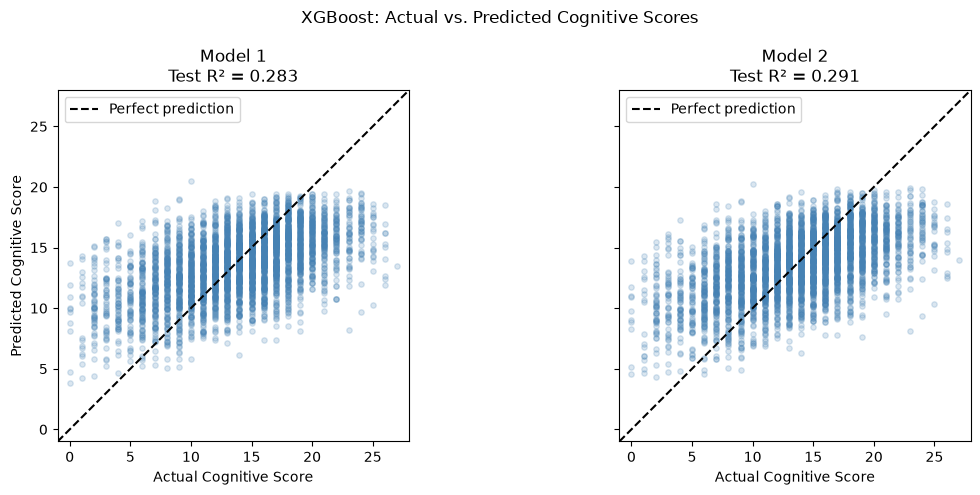

In [16]:
import matplotlib.pyplot as plt

# Use the same axis range for both models
lower = min(
    0,
    Y_testset.min(),
    Y_pred_xgb_m1.min(),
    Y_pred_xgb_m2.min(),
) - 1

upper = max(
    27,
    Y_testset.max(),
    Y_pred_xgb_m1.max(),
    Y_pred_xgb_m2.max(),
) + 1

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharex=True,
    sharey=True,
)

for ax, name, predictions in [
    (axes[0], "Model 1", Y_pred_xgb_m1),
    (axes[1], "Model 2", Y_pred_xgb_m2),
]:
    ax.scatter(
        Y_testset,
        predictions,
        alpha=0.2,
        s=15,
        color="steelblue",
    )

    ax.plot(
        [lower, upper],
        [lower, upper],
        "--",
        color="black",
        label="Perfect prediction",
    )

    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel("Actual Cognitive Score")
    ax.set_title(
        f"{name}\nTest R² = {xgb_results.loc[name, 'R²']:.3f}"
    )
    ax.legend()

axes[0].set_ylabel("Predicted Cognitive Score")

fig.suptitle("XGBoost: Actual vs. Predicted Cognitive Scores")
fig.tight_layout()

fig.savefig(
    "xgb_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## Step 10 — Set Up Cross-Validation for Hyperparameter Tuning

Divide the existing training set into five folds.

For each parameter combination, train on four folds and validate on the remaining fold. Repeat until each fold has been used for validation.

Use the same folds for Model 1 and Model 2. Keep the original test set separate from hyperparameter tuning.

In [17]:
from sklearn.model_selection import KFold

# Confirm that both models use the same training rows and order
assert X1_trainset.index.equals(X2_trainset.index)
assert X1_trainset.index.equals(Y_trainset.index)

# Define five-fold cross-validation
xgb_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=3,
)

# Save the folds so both models use exactly the same splits
xgb_cv_splits = list(xgb_cv.split(X1_trainset))

print(f"Cross-validation folds: {len(xgb_cv_splits)}")

train_rows, validation_rows = xgb_cv_splits[0]
print(f"First fold — training records: {len(train_rows):,}")
print(f"First fold — validation records: {len(validation_rows):,}")

Cross-validation folds: 5
First fold — training records: 7,309
First fold — validation records: 1,828


## Step 11 — Define the Hyperparameter Grid

Specify candidate values for the number of trees, maximum tree depth, and learning rate.

Use the same parameter grid for both models. Include the initial settings: 300 trees, a maximum depth of 3, and a learning rate of 0.05.

Keep the remaining hyperparameters fixed. Parameter combinations will be evaluated using the five-fold cross-validation splits.

In [18]:
from sklearn.model_selection import ParameterGrid

xgb_param_grid = {
    "regression__n_estimators": [100, 300, 500],
    "regression__max_depth": [2, 3, 5],
    "regression__learning_rate": [0.03, 0.05, 0.10],
}

n_combinations = len(list(ParameterGrid(xgb_param_grid)))

print(f"Parameter combinations: {n_combinations}")
print(
    "Cross-validation fits per model:",
    n_combinations * len(xgb_cv_splits),
)

Parameter combinations: 27
Cross-validation fits per model: 135


## Step 12 — Tune Model 1

Use GridSearchCV to evaluate all 27 parameter combinations with the predefined five-fold splits.

Select the combination with the lowest mean validation RMSE, then refit the selected pipeline on the full training set.

Fit preprocessing separately within each fold and allow unseen categories during validation. Keep the original model as a baseline and leave the test set out of tuning.

In [19]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV

# Create an independent, untrained copy of the original pipeline
xgb_tuning_model1 = clone(xgb_model1)

# Allow categories that may be absent from an individual training fold
xgb_tuning_model1.set_params(
    preprocessor__categorical__handle_unknown="ignore"
)

# Define the parameter search
xgb_search_m1 = GridSearchCV(
    estimator=xgb_tuning_model1,
    param_grid=xgb_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=xgb_cv_splits,
    refit=True,
    n_jobs=1,
    verbose=1,
    error_score="raise",
)

# Tune using the training set only
xgb_search_m1.fit(X1_trainset, Y_trainset)

# Save the selected and refitted pipeline
xgb_tuned_model1 = xgb_search_m1.best_estimator_

print("Selected parameters for Model 1:")
print(xgb_search_m1.best_params_)

print(
    "Mean validation RMSE:",
    round(-xgb_search_m1.best_score_, 4),
)

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Selected parameters for Model 1:
{'regression__learning_rate': 0.1, 'regression__max_depth': 2, 'regression__n_estimators': 100}
Mean validation RMSE: 4.189


## Step 13 — Tune Model 2

Tune Model 2 using the same parameter grid, cross-validation folds, preprocessing policy, and RMSE scoring as Model 1.

Select the combination with the lowest mean validation RMSE, then refit the selected pipeline on the full training set.

Model 2 adds Chronic Disease Burden. Its selected parameters may differ from those of Model 1. Keep the test set out of tuning.

In [20]:
# Create an independent, untrained copy of Model 2
xgb_tuning_model2 = clone(xgb_model2)

# Use the same categorical handling as tuned Model 1
xgb_tuning_model2.set_params(
    preprocessor__categorical__handle_unknown="ignore"
)

# Define the parameter search
xgb_search_m2 = GridSearchCV(
    estimator=xgb_tuning_model2,
    param_grid=xgb_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=xgb_cv_splits,
    refit=True,
    n_jobs=1,
    verbose=1,
    error_score="raise",
)

# Tune using the training set only
xgb_search_m2.fit(X2_trainset, Y_trainset)

# Save the selected and refitted pipeline
xgb_tuned_model2 = xgb_search_m2.best_estimator_

print("Selected parameters for Model 2:")
print(xgb_search_m2.best_params_)

print(
    "Mean validation RMSE:",
    round(-xgb_search_m2.best_score_, 4),
)

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Selected parameters for Model 2:
{'regression__learning_rate': 0.03, 'regression__max_depth': 2, 'regression__n_estimators': 300}
Mean validation RMSE: 4.1788


## Step 14 — Predict Test-Set Scores with the Tuned Models

Use the tuned models to predict Cognitive Scores for the original test participants.

Apply the preprocessing learned from the full training set without refitting.

Save the tuned predictions separately from the baseline predictions for later comparison.

In [21]:
# Predict using the tuned models
Y_pred_xgb_tuned_m1 = xgb_tuned_model1.predict(X1_testset)
Y_pred_xgb_tuned_m2 = xgb_tuned_model2.predict(X2_testset)

# Display predictions alongside the actual scores
xgb_tuned_prediction_results = pd.DataFrame(
    {
        "Actual Cognitive Score": Y_testset,
        "Tuned Model 1 Prediction": Y_pred_xgb_tuned_m1,
        "Tuned Model 2 Prediction": Y_pred_xgb_tuned_m2,
    },
    index=Y_testset.index,
)

display(xgb_tuned_prediction_results.head(10))

,Actual Cognitive Score,Tuned Model 1 Prediction,Tuned Model 2 Prediction
3277,15.0,13.525324,13.461889
1411,8.0,12.985879,13.108306
2877,14.0,11.068093,11.285036
4242,16.0,14.229561,14.206023
8473,18.0,17.298904,17.427240
9176,12.0,16.042479,15.729345
11635,10.0,15.692281,15.802819
7962,18.0,16.322451,16.228561
8378,16.0,14.874597,14.911004
4227,12.0,16.324738,16.382565


## Step 15 — Compare Baseline and Tuned Model Performance

Calculate test-set MAE, RMSE, and R² for the tuned models.

Compare all four results on the same test participants:
- Baseline Model 1 and Model 2.
- Tuned Model 1 and Model 2.

Lower MAE and RMSE indicate better predictions, while higher R² indicates better performance.

In [22]:
# Evaluate the tuned models on the test set
xgb_tuned_results = pd.DataFrame(
    [
        evaluate_xgb_regression(Y_testset, Y_pred_xgb_tuned_m1),
        evaluate_xgb_regression(Y_testset, Y_pred_xgb_tuned_m2),
    ],
    index=["Model 1", "Model 2"],
)

# Combine the baseline and tuned results
xgb_comparison_results = pd.concat(
    [xgb_results, xgb_tuned_results],
    keys=["Baseline", "Tuned"],
    names=["Settings", "Model"],
)

display(xgb_comparison_results.round(4))

MAE    RMSE      R²
Settings Model                          
Baseline Model 1  3.3422  4.2222  0.2829
         Model 2  3.3246  4.1998  0.2905
Tuned    Model 1  3.3376  4.2092  0.2873
         Model 2  3.3263  4.1953  0.2920

## Step 16 — Visualize Predictions from the Tuned Models

Plot actual Cognitive Scores against predictions from the tuned XGBoost models.

Use the same test participants and axis scales for both panels. The dashed diagonal line represents perfect prediction.

Points closer to the line indicate smaller prediction errors.

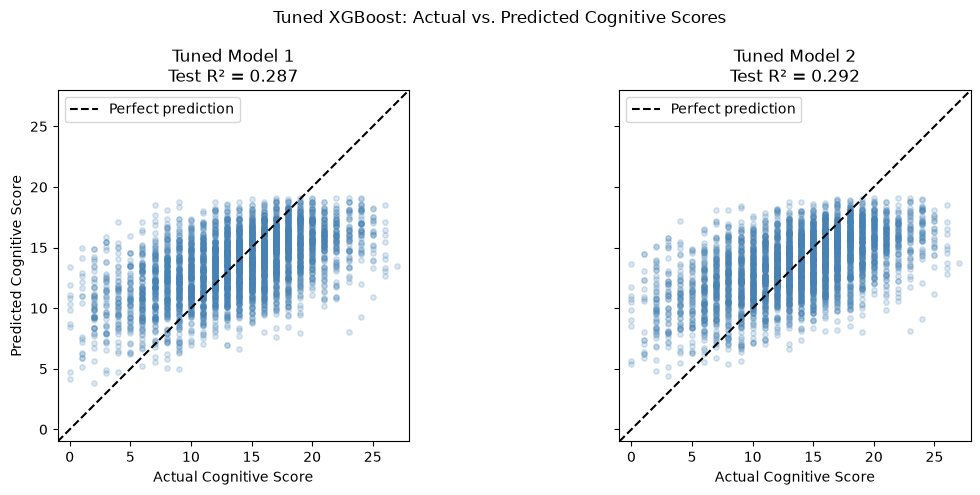

In [23]:
import matplotlib.pyplot as plt

# Use the same axis range for both tuned models
lower = min(
    0,
    Y_testset.min(),
    Y_pred_xgb_tuned_m1.min(),
    Y_pred_xgb_tuned_m2.min(),
) - 1

upper = max(
    27,
    Y_testset.max(),
    Y_pred_xgb_tuned_m1.max(),
    Y_pred_xgb_tuned_m2.max(),
) + 1

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharex=True,
    sharey=True,
)

for ax, name, predictions in [
    (axes[0], "Model 1", Y_pred_xgb_tuned_m1),
    (axes[1], "Model 2", Y_pred_xgb_tuned_m2),
]:
    ax.scatter(
        Y_testset,
        predictions,
        alpha=0.2,
        s=15,
        color="steelblue",
    )

    ax.plot(
        [lower, upper],
        [lower, upper],
        "--",
        color="black",
        label="Perfect prediction",
    )

    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel("Actual Cognitive Score")
    ax.set_title(
        f"Tuned {name}\n"
        f"Test R² = {xgb_tuned_results.loc[name, 'R²']:.3f}"
    )
    ax.legend()

axes[0].set_ylabel("Predicted Cognitive Score")

fig.suptitle(
    "Tuned XGBoost: Actual vs. Predicted Cognitive Scores"
)
fig.tight_layout()

fig.savefig(
    "xgb_tuned_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## Step 17 — Compare Residuals Across Baseline and Tuned Models

Calculate residuals as actual minus predicted Cognitive Scores.

Create four panels:
- Top row: Baseline Model 1 and Model 2.
- Bottom row: Tuned Model 1 and Model 2.

Plot residuals against predicted scores using the same axis scales. The horizontal line at zero represents no prediction error.

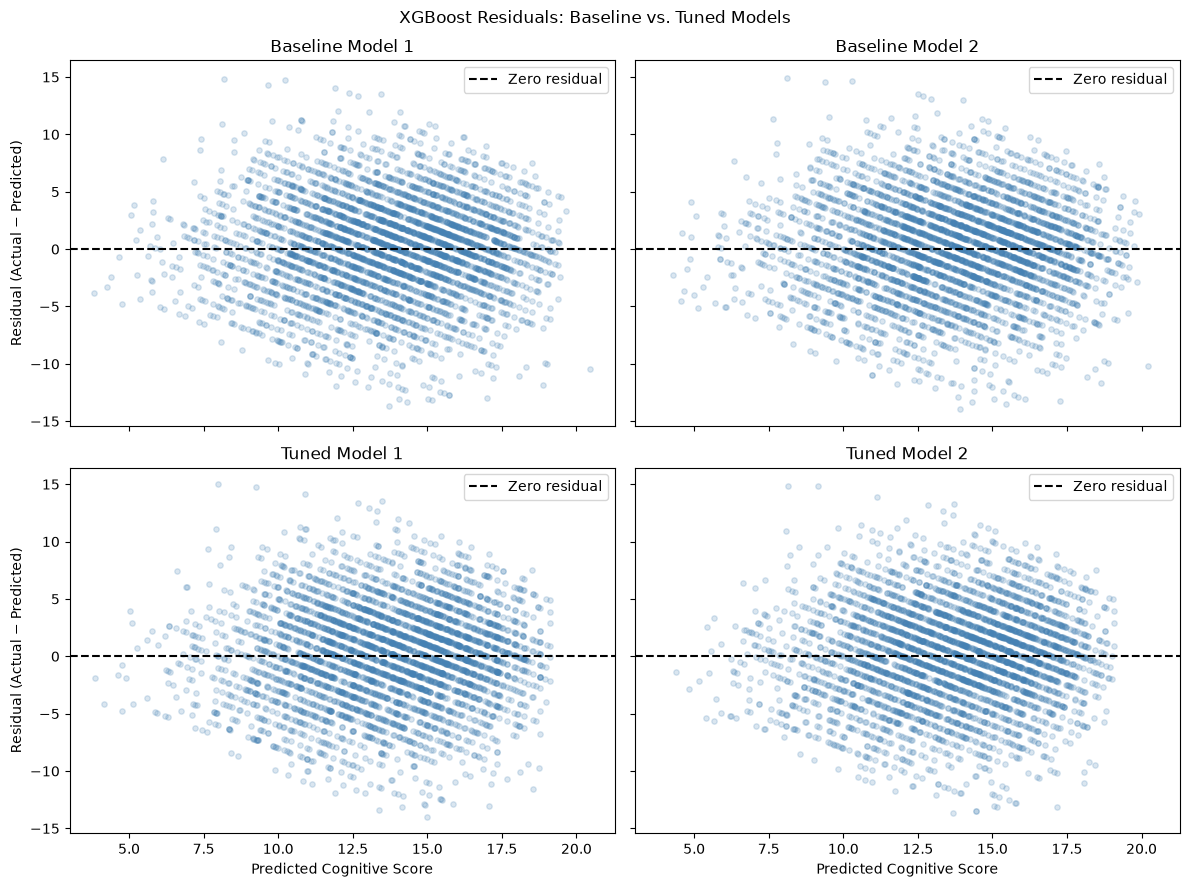

In [24]:
import matplotlib.pyplot as plt

actual_scores = Y_testset.to_numpy()

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 9),
    sharex=True,
    sharey=True,
)

panels = [
    (axes[0, 0], "Baseline Model 1", Y_pred_xgb_m1),
    (axes[0, 1], "Baseline Model 2", Y_pred_xgb_m2),
    (axes[1, 0], "Tuned Model 1", Y_pred_xgb_tuned_m1),
    (axes[1, 1], "Tuned Model 2", Y_pred_xgb_tuned_m2),
]

for ax, name, predictions in panels:
    # Residual = actual score - predicted score
    residuals = actual_scores - predictions

    ax.scatter(
        predictions,
        residuals,
        alpha=0.2,
        s=15,
        color="steelblue",
    )

    ax.axhline(
        y=0,
        linestyle="--",
        color="black",
        label="Zero residual",
    )

    ax.set_title(name)
    ax.legend()

# Label the bottom row and left column
for ax in axes[1, :]:
    ax.set_xlabel("Predicted Cognitive Score")

for ax in axes[:, 0]:
    ax.set_ylabel("Residual (Actual − Predicted)")

fig.suptitle(
    "XGBoost Residuals: Baseline vs. Tuned Models"
)
fig.tight_layout()

fig.savefig(
    "xgb_baseline_vs_tuned_residuals.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()